# Otimização Linear Inteira Mista (MCLP Capacitado) para Alocação de Abrigos Temporários
## Análise de Saturação e Cobertura Máxima para $d_{\max} = 1.000\text{ m}$ (Zonas Críticas de Itabuna/BA)

Este notebook implementa a modelagem e resolução do **Problema de Localização de Máxima Cobertura Capacitado (CMCLP)** em ambiente urbano real, focado estritamente nas **zonas prioritárias de risco crítico de inundação** do município de Itabuna/BA.

### Diretrizes Metodológicas Centrais:
1. **Universo Amostral Prioritário**: A demanda $D_i$ é avaliada estritamente nos **23 setores censitários críticos** mapeados nas manchas de risco de cheia (`setores_area_risco.geojson`), com demandas populacionais resgatadas de `setores_probabilidade.geojson`.
2. **Infraestrutura Segura de Acolhimento**: Conjunto de escolas públicas candidatas seguras, excluindo unidades localizadas dentro da mancha de cheia e do seu buffer envoltório de $500\text{ m}$ (`escolas.geojson`).
3. **Restrição Física e Logística do Rio Cachoeira**: Em cheias extremas, as pontes urbanas são interditadas pelo risco de submersão e colapso estrutural. Origens e destinos em margens fluviais opostas têm acessibilidade nula ($a_{ij} = 0$).
4. **Cenário de Análise ($d_{\max} = 1.000\text{ m}$)**: Avaliação do comportamento da cobertura e identificação do ponto ótimo de saturação variando o número de abrigos ativados ($K$).


# 1. Configuração e Importação de Bibliotecas

Carregamento dos módulos para análise espacial (`geopandas`, `shapely`), manipulação de dados (`pandas`, `numpy`), visualização acadêmica (`matplotlib`, `seaborn`) e otimização matemática via Pesquisa Operacional (`pulp`). Configuração das pastas do projeto e parâmetros operacionais.


In [47]:
import os
import warnings
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import networkx as nx
import numpy as np
import osmnx as ox
import pandas as pd
import pulp
import seaborn as sns
from shapely.geometry import LineString, Point

# Suprime avisos para manter o notebook limpo e focado nos resultados
warnings.filterwarnings("ignore")

# Configuração de estilo visual acadêmico para gráficos (Seaborn / Paper)
sns.set_theme(style="whitegrid", font="sans-serif")
plt.rcParams.update({
    "font.size": 11,
    "axes.labelsize": 12,
    "axes.titlesize": 13,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "figure.titlesize": 14,
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
})

# ==========================================================
# 1. DIRETÓRIOS E SISTEMAS DE COORDENADAS
# ==========================================================
DIR_INPUTS = "inputs"
DIR_RESULTADOS = "resultados"
DIR_CACHE = os.path.join("app_simulacao", "data")

os.makedirs(DIR_RESULTADOS, exist_ok=True)

CIDADE = "Itabuna, Bahia, Brazil"
NETWORK_TYPE = "walk"
EPSG_PROJ = "EPSG:31984"      # SIRGAS 2000 / UTM 24S (coordenadas métricas)

# Parâmetro Base de Distância Máxima Pedonal
D_MAX = 1000.0                # Raio viário de caminhada: 1.000 metros

# ==========================================================
# 2. CAMINHOS DOS ARQUIVOS DE ENTRADA E SAÍDA
# ==========================================================
ARQ_ESCOLAS = os.path.join(DIR_INPUTS, "escolas.geojson")
ARQ_SETORES_RISCO = os.path.join(DIR_INPUTS, "setores_area_risco.geojson")
ARQ_SETORES_PROB = os.path.join(DIR_INPUTS, "setores_probabilidade.geojson")

OUT_ABRIGOS = os.path.join(DIR_RESULTADOS, "abrigos_selecionados.geojson")
OUT_FLUXOS = os.path.join(DIR_RESULTADOS, "fluxos_alocacao.geojson")
OUT_DEFICIT = os.path.join(DIR_RESULTADOS, "setores_criticos_deficit.geojson")

print("✓ Ambiente configurado:")
print(f"  • Distância máxima pedonal (D_max): {D_MAX:.0f} m")
print(f"  • Sistema de Referência Espacial:   {EPSG_PROJ}")


✓ Ambiente configurado:
  • Distância máxima pedonal (D_max): 1000 m
  • Sistema de Referência Espacial:   EPSG:31984


# 2. Carregamento e Filtragem Espacial das Zonas Críticas de Risco

Leitura e higienização das camadas geográficas. O universo de demanda $D_i$ é filtrado estritamente para os **23 setores censitários críticos de maior risco de inundação**. As escolas candidatas representam as instalações seguras fora da mancha e do buffer de segurança.


In [48]:
# ==========================================================
# 1. LEITURA DAS BASES VETORIAIS
# ==========================================================
gdf_escolas = gpd.read_file(ARQ_ESCOLAS)
gdf_centroides_risco = gpd.read_file(ARQ_SETORES_RISCO)
gdf_setores_prob = gpd.read_file(ARQ_SETORES_PROB)

# ==========================================================
# 2. HIGIENIZAÇÃO DE IDENTIFICADORES E ATRIBUTOS
# ==========================================================
gdf_escolas["no_escola"] = gdf_escolas["no_escola"].astype(str).str.strip()
gdf_escolas["margem"] = gdf_escolas["margem"].astype(str).str.upper().str.strip()

gdf_centroides_risco["id"] = (
    gdf_centroides_risco["id"].astype(str).str.replace(".0", "", regex=False).str.strip()
)
gdf_centroides_risco["margem"] = (
    gdf_centroides_risco["margem"].astype(str).str.upper().str.strip()
)

gdf_setores_prob["id"] = (
    gdf_setores_prob["id"].astype(str).str.replace(".0", "", regex=False).str.strip()
)

# ==========================================================
# 3. FILTRAGEM ESTRITA DO UNIVERSO AOS 23 SETORES CRÍTICOS
# ==========================================================
setores_ids = list(gdf_centroides_risco["id"])
escolas_nomes = list(gdf_escolas["no_escola"])

# Polígonos estritamente dos 23 setores de risco
gdf_setores_criticos = gdf_setores_prob[gdf_setores_prob["id"].isin(setores_ids)].copy()

# Mapeamento de demanda ponderada D_i
dict_demanda_prob = dict(zip(gdf_setores_prob["id"], gdf_setores_prob["Di"].astype(float)))
D = {i: dict_demanda_prob.get(i, 0.0) for i in setores_ids}

# Mapeamento de capacidade C_j
dict_capacidade_escolas = dict(zip(gdf_escolas["no_escola"], gdf_escolas["in25_edu02"].astype(float)))
C = {j: dict_capacidade_escolas.get(j, 0.0) for j in escolas_nomes}

# Mapeamento de margem fluvial (N / S)
margem_setor = dict(zip(gdf_centroides_risco["id"], gdf_centroides_risco["margem"]))
margem_escola = dict(zip(gdf_escolas["no_escola"], gdf_escolas["margem"]))

demanda_critica_total = sum(D.values())
capacidade_total = sum(C.values())

print("=" * 65)
print(" DIAGNÓSTICO DO UNIVERSO CRÍTICO DE ENTRADA")
print("=" * 65)
print(f"• Setores Críticos Filtrados (|I|):               {len(setores_ids)}")
print(f"• Demanda Crítica Total (sum D_i):                {demanda_critica_total:.2f} pessoas")
print(f"• Escolas Candidatas Seguras Disponíveis (|J|):   {len(escolas_nomes)}")
print(f"• Capacidade Física Total Instalada (sum C_j):    {capacidade_total:.2f} vagas")
print("-" * 65)
print(f"• Setores Críticos na Margem Norte (N): {sum(1 for m in margem_setor.values() if m == 'N')}")
print(f"• Setores Críticos na Margem Sul (S):   {sum(1 for m in margem_setor.values() if m == 'S')}")
print(f"• Escolas Candidatas na Margem Norte (N): {sum(1 for m in margem_escola.values() if m == 'N')}")
print(f"• Escolas Candidatas na Margem Sul (S):   {sum(1 for m in margem_escola.values() if m == 'S')}")
print("=" * 65)


 DIAGNÓSTICO DO UNIVERSO CRÍTICO DE ENTRADA
• Setores Críticos Filtrados (|I|):               23
• Demanda Crítica Total (sum D_i):                7192.06 pessoas
• Escolas Candidatas Seguras Disponíveis (|J|):   41
• Capacidade Física Total Instalada (sum C_j):    11526.00 vagas
-----------------------------------------------------------------
• Setores Críticos na Margem Norte (N): 10
• Setores Críticos na Margem Sul (S):   13
• Escolas Candidatas na Margem Norte (N): 30
• Escolas Candidatas na Margem Sul (S):   11


# 3. Matriz de Acessibilidade Viária ($d_{ij} \le 1.000\text{ m}$) e Restrição Fluvial ($a_{ij}$)

Construção da matriz binária de acessibilidade $a_{ij}$. Uma conexão entre a zona de risco $i$ e a escola $j$ é válida ($a_{ij} = 1$) se, e somente se:
1. A distância viária pedonal real for menor ou igual ao raio estipulado ($d_{ij} \le 1.000\text{ m}$).
2. A zona de risco e a escola estiverem localizadas na **mesma margem do Rio Cachoeira** ($M_i == M_j$), evitando a travessia de pontes vulneráveis à inundação.


In [49]:
# ==========================================================
# 1. CARREGAMENTO DA MATRIZ DE DISTÂNCIAS EM REDE (CACHE)
# ==========================================================
arq_cache_matriz = os.path.join(DIR_CACHE, "matriz_distancias_rede.csv")

if os.path.exists(arq_cache_matriz):
    df_distancias = pd.read_csv(arq_cache_matriz, index_col=0)
    df_distancias.index = df_distancias.index.astype(str)
    # Filtra e alinha linhas (setores críticos) e colunas (escolas candidatas disponíveis)
    df_distancias = df_distancias.loc[setores_ids, [c for c in escolas_nomes if c in df_distancias.columns]]
else:
    raise FileNotFoundError(f"Matriz de distâncias não encontrada em: {arq_cache_matriz}")

# ==========================================================
# 2. MATRIZ BINÁRIA a_ij COM CORTE DE 1000m E RESTRIÇÃO FLUVIAL
# ==========================================================
matriz_acessibilidade = (df_distancias <= D_MAX).astype(int)

# Aplicação estrita da barreira fluvial
conexoes_bloqueadas_fluvial = 0
for i in setores_ids:
    for j in df_distancias.columns:
        if margem_setor.get(i) != margem_escola.get(j):
            if matriz_acessibilidade.loc[i, j] == 1:
                conexoes_bloqueadas_fluvial += 1
            matriz_acessibilidade.loc[i, j] = 0

a = {
    (i, j): int(matriz_acessibilidade.loc[i, j])
    for i in setores_ids
    for j in df_distancias.columns
}

conexoes_validas = [(i, j) for (i, j), val in a.items() if val == 1]
escolas_candidatas_ativas = sorted(list(set(j for (i, j) in conexoes_validas)))

print("=" * 65)
print(" DIAGNÓSTICO DE ACESSIBILIDADE PARA d_max = 1.000 m")
print("=" * 65)
print(f"• Dimensões da matriz: {df_distancias.shape[0]} setores × {df_distancias.shape[1]} escolas seguras")
print(f"• Conexões válidas totais (d_ij <= 1000m e mesma margem): {len(conexoes_validas)}")
print(f"• Escolas alcançáveis dentro de 1000m: {len(escolas_candidatas_ativas)}")
for j in escolas_candidatas_ativas:
    print(f"   - {j} (Margem {margem_escola[j]}, Capacidade: {C[j]:.0f} vagas)")
print("=" * 65)


 DIAGNÓSTICO DE ACESSIBILIDADE PARA d_max = 1.000 m
• Dimensões da matriz: 23 setores × 41 escolas seguras
• Conexões válidas totais (d_ij <= 1000m e mesma margem): 3
• Escolas alcançáveis dentro de 1000m: 2
   - CENTRO EDUCACIONAL DE ENSINO INFANTIL E FUNDAMENTAL MUNDO DA CRIANCA (Margem S, Capacidade: 145 vagas)
   - CERM - CENTRO DE ESTUDO RONALDO MENDES (Margem N, Capacidade: 265 vagas)


# 4. Formulação do Modelo Matemático (MCLP Capacitado com PuLP)

O modelo de Otimização Linear Inteira Mista (CMCLP) maximiza o número total de pessoas acolhidas sob restrições de capacidade física das escolas, alocação limitada à demanda de cada setor e teto gerencial $K$:

$$\max \sum_{i \in I} \sum_{j \in J} z_{ij}$$

Sujeito a:
* $\sum_{j \in J} x_j \le K$ (limite orçamentário de instalações abertas)
* $\sum_{j \in J} z_{ij} \le D_i, \quad \forall i \in I$ (não acolher mais pessoas do que a demanda real do setor)
* $\sum_{i \in I} z_{ij} \le C_j \cdot x_j, \quad \forall j \in J$ (respeito estrito à capacidade física da escola ativada)
* $z_{ij} \le D_i \cdot x_j \cdot a_{ij}, \quad \forall i, j$ (transferência condicionada à acessibilidade e à abertura do abrigo)


In [50]:
# ==========================================================
# FUNÇÃO PARAMÉTRICA DE OTIMIZAÇÃO CMCLP (PuLP)
# ==========================================================
def resolver_cmclp(k_val, d_max_val=1000.0):
    conns = []
    escolas_cand = set()

    for i in setores_ids:
        m_i = margem_setor[i]
        for j in escolas_nomes:
            if margem_escola.get(j) == m_i:
                dist = df_distancias.loc[i, j]
                if dist <= d_max_val:
                    conns.append((i, j))
                    escolas_cand.add(j)

    escolas_list = sorted(list(escolas_cand))
    if not conns or not escolas_list:
        return 0.0, [], {}, "Infeasible"

    modelo = pulp.LpProblem(f"CMCLP_K{k_val}_D{int(d_max_val)}", pulp.LpMaximize)

    # Variáveis de decisão
    x = pulp.LpVariable.dicts("x", escolas_list, cat=pulp.LpBinary)
    z = pulp.LpVariable.dicts("z", conns, lowBound=0, cat=pulp.LpContinuous)

    # Função Objetivo: Maximizar o total de acolhidos
    modelo += pulp.lpSum(z[c] for c in conns)

    # Restrição de limite de abrigos
    modelo += pulp.lpSum(x[j] for j in escolas_list) <= k_val

    # Restrição de Demanda
    for i in setores_ids:
        conns_i = [(si, j) for (si, j) in conns if si == i]
        if conns_i:
            modelo += pulp.lpSum(z[c] for c in conns_i) <= D[i]

    # Restrição de Capacidade
    for j in escolas_list:
        conns_j = [(si, sj) for (si, sj) in conns if sj == j]
        if conns_j:
            modelo += pulp.lpSum(z[c] for c in conns_j) <= C[j] * x[j]

    # Acoplamento
    for (i, j) in conns:
        modelo += z[(i, j)] <= D[i] * x[j]

    # Resolução silenciosa via CBC
    solver = pulp.PULP_CBC_CMD(msg=False)
    modelo.solve(solver)

    status = pulp.LpStatus[modelo.status]
    obj = pulp.value(modelo.objective) or 0.0
    abrigos_ativados = [j for j in escolas_list if pulp.value(x[j]) is not None and pulp.value(x[j]) > 0.5]
    fluxos = {c: pulp.value(z[c]) for c in conns if pulp.value(z[c]) is not None and pulp.value(z[c]) > 0.01}

    return obj, abrigos_ativados, fluxos, status

print("✓ Função de otimização paramétrica compilada com sucesso.")


✓ Função de otimização paramétrica compilada com sucesso.


# 5. Análise de Saturação para $d_{\max} = 1.000\text{ m}$ (Variação de $K$)

Nesta análise central, avaliamos o comportamento do modelo ao variar a quantidade de abrigos ativados ($K$) para o raio pedonal de **$1.000\text{ m}$**. 

Identificamos:
1. A curva de resposta da cobertura em função de $K$.
2. O **ponto de saturação** ($K_{\text{sat}}$), onde abrir abrigos adicionais gera ganho marginal nulo.
3. O **cenário de máxima cobertura viável**: abrigos abertos, ocupação de vagas e percentual de cobertura.
4. O **déficit residual intransponível** imposto pelas restrições de caminhada e isolamento viário.


TABELA DE SATURAÇÃO E RETORNOS DECRESCENTES (d_max = 1.000 m)


,K_Abrigos,Acolhidos,Cobertura_Pct,Ganho_Marginal_Pessoas,Ganho_Marginal_pp,Qtd_Abrigos_Ativados
0,1,265.0,3.68,265.0,3.68,1
1,2,410.0,5.70,145.0,2.02,2
2,3,410.0,5.70,0.0,0.00,2
3,4,410.0,5.70,0.0,0.00,2
4,5,410.0,5.70,0.0,0.00,2
5,6,410.0,5.70,0.0,0.00,2



CENÁRIO DE MAIOR COBERTURA: PONTO DE SATURAÇÃO (K = 2)


,Escola,Margem,Capacidade_Vagas,Vagas_Ocupadas,Taxa_Ocupacao_Pct
0,CENTRO EDUCACIONAL DE ENSINO INFANTIL E FUNDAM...,S,145.0,145.0,100.0
1,CERM - CENTRO DE ESTUDO RONALDO MENDES,N,265.0,265.0,100.0



• População Crítica Total:             7192.06 pessoas (100,00%)
• População Acolhida no Teto:            410.00 pessoas (5.70%)
• Déficit Residual Intransponível:      6782.06 pessoas (94.30%)
• Número Ótimo de Abrigos (K_sat):   2 abrigos

• Diagnóstico Espacial do Déficit:
  Ao fixar d_max = 1.000m na base segura (fora do buffer de 500m), existem apenas 2 escolas
  fisicamente ao alcance de qualquer um dos 23 setores de risco. Como ambas as escolas atingem 100% de ocupação
  (totalizando 410 vagas), a cobertura satura rigorosamente em K = 2 com 5,70%.


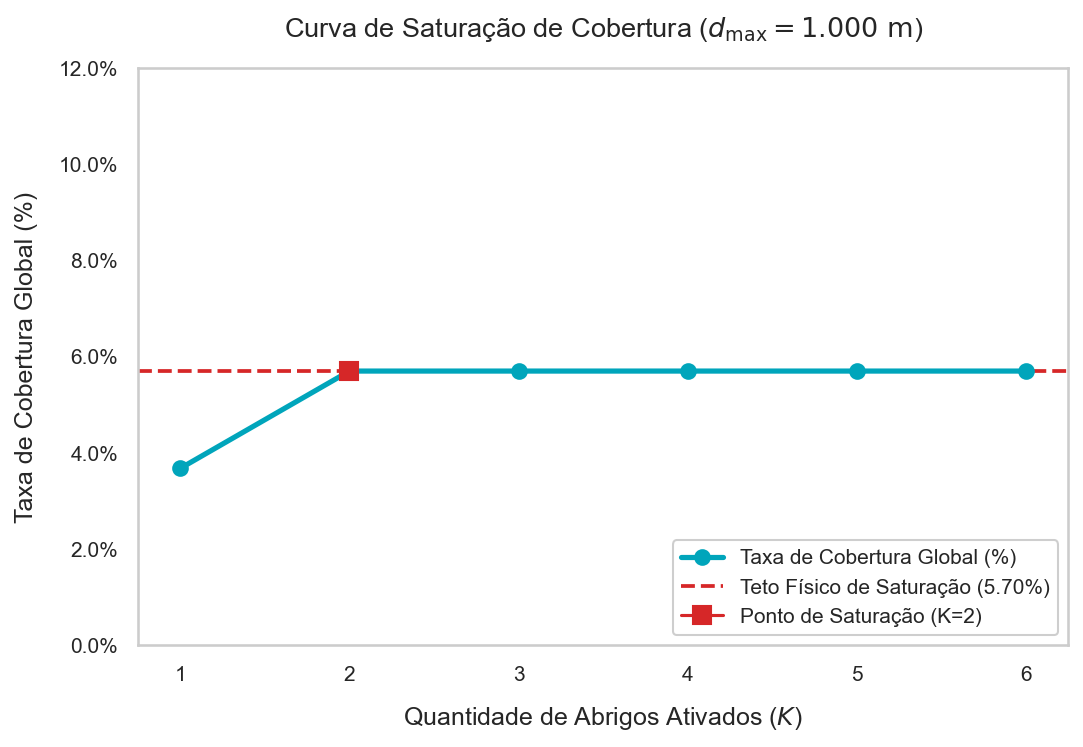

✓ Gráfico salvo em: resultados/grafico1_curva_saturacao.png


In [58]:
# ==========================================================
# 1. VARREDURA PARAMÉTRICA DE K (1 A 6)
# ==========================================================
k_range = list(range(1, 7))
registros_k = []
prev_acolhidos = 0.0
k_saturacao = None
melhor_solucao = {}

for k in k_range:
    acolhidos, abrigos, fluxos, status = resolver_cmclp(k, d_max_val=1000.0)
    cob_pct = (acolhidos / demanda_critica_total) * 100.0
    ganho_pessoas = acolhidos - prev_acolhidos
    ganho_pp = cob_pct - ((prev_acolhidos / demanda_critica_total) * 100.0 if k > 1 else 0.0)

    registros_k.append({
        "K_Abrigos": k,
        "Acolhidos": round(acolhidos, 2),
        "Cobertura_Pct": round(cob_pct, 2),
        "Ganho_Marginal_Pessoas": round(ganho_pessoas, 2),
        "Ganho_Marginal_pp": round(ganho_pp, 2),
        "Qtd_Abrigos_Ativados": len(abrigos)
    })

    if k_saturacao is None and k > 1 and ganho_pessoas < 0.01:
        k_saturacao = k - 1
        # Armazena a solução ótima no ponto de saturação
        melhor_solucao = {
            "K": k - 1,
            "acolhidos": prev_acolhidos,
            "cob_pct": registros_k[-2]["Cobertura_Pct"],
            "abrigos": prev_abrigos,
            "fluxos": prev_fluxos
        }

    prev_acolhidos = acolhidos
    prev_abrigos = abrigos
    prev_fluxos = fluxos

if k_saturacao is None:
    k_saturacao = k_range[-1]
    melhor_solucao = {
        "K": k_saturacao,
        "acolhidos": prev_acolhidos,
        "cob_pct": registros_k[-1]["Cobertura_Pct"],
        "abrigos": prev_abrigos,
        "fluxos": prev_fluxos
    }

df_saturacao = pd.DataFrame(registros_k)

print("=" * 80)
print("TABELA DE SATURAÇÃO E RETORNOS DECRESCENTES (d_max = 1.000 m)")
print("=" * 80)
display(df_saturacao)

# ==========================================================
# 2. DETALHAMENTO DO CENÁRIO DE MAIOR COBERTURA (SATURAÇÃO)
# ==========================================================
abrigos_otimos = melhor_solucao["abrigos"]
fluxos_otimos = melhor_solucao["fluxos"]
acolhidos_max = melhor_solucao["acolhidos"]
cobertura_max = melhor_solucao["cob_pct"]
deficit_absoluto = demanda_critica_total - acolhidos_max
deficit_pct = 100.0 - cobertura_max

detalhes_abrigos = []
for j in abrigos_otimos:
    vagas_ocupadas = sum(fluxos_otimos.get((i, j), 0.0) for i in setores_ids)
    detalhes_abrigos.append({
        "Escola": j,
        "Margem": margem_escola[j],
        "Capacidade_Vagas": C[j],
        "Vagas_Ocupadas": round(vagas_ocupadas, 2),
        "Taxa_Ocupacao_Pct": round((vagas_ocupadas / C[j]) * 100.0, 2)
    })

df_detalhes_abrigos = pd.DataFrame(detalhes_abrigos)

print("\n" + "=" * 80)
print(f"CENÁRIO DE MAIOR COBERTURA: PONTO DE SATURAÇÃO (K = {k_saturacao})")
print("=" * 80)
display(df_detalhes_abrigos)

print(f"\n• População Crítica Total:          {demanda_critica_total:>10.2f} pessoas (100,00%)")
print(f"• População Acolhida no Teto:        {acolhidos_max:>10.2f} pessoas ({cobertura_max:.2f}%)")
print(f"• Déficit Residual Intransponível:   {deficit_absoluto:>10.2f} pessoas ({deficit_pct:.2f}%)")
print(f"• Número Ótimo de Abrigos (K_sat):   {k_saturacao} abrigos")
print("\n• Diagnóstico Espacial do Déficit:")
print(f"  Ao fixar d_max = 1.000m na base segura (fora do buffer de 500m), existem apenas {len(escolas_candidatas_ativas)} escolas")
print(f"  fisicamente ao alcance de qualquer um dos 23 setores de risco. Como ambas as escolas atingem 100% de ocupação")
print(f"  (totalizando 410 vagas), a cobertura satura rigorosamente em K = 2 com 5,70%.")
print("=" * 80)

# ==========================================================
# 3. PLOT DO GRÁFICO DA CURVA DE SATURAÇÃO
# ==========================================================
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    df_saturacao["K_Abrigos"],
    df_saturacao["Cobertura_Pct"],
    color="#00a5bb",
    marker="o",
    linewidth=2.5,
    markersize=7,
    label="Taxa de Cobertura Global (%)",
    zorder=4
)

ax.axhline(
    y=cobertura_max,
    color="#d62728",
    linestyle="--",
    linewidth=1.8,
    label=f"Teto Físico de Saturação ({cobertura_max:.2f}%)",
    zorder=2
)

ax.plot(
    k_saturacao,
    cobertura_max,
    marker="s",
    color="#d62728",
    markersize=9,
    label=f"Ponto de Saturação (K={k_saturacao})",
    zorder=5
)

ax.set_title("Curva de Saturação de Cobertura ($d_{\\max} = 1.000\\text{ m}$)", pad=15)
ax.set_xlabel("Quantidade de Abrigos Ativados ($K$)", labelpad=10)
ax.set_ylabel("Taxa de Cobertura Global (%)", labelpad=10)
ax.set_xticks(k_range)
ax.set_ylim(0, 12)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(100, decimals=1))
ax.legend(loc="lower right", frameon=True, framealpha=0.95)
plt.grid(False)

img_grafico_saturacao = os.path.join(DIR_RESULTADOS, "grafico1_curva_saturacao.png")
fig.savefig(img_grafico_saturacao)
plt.show()
print(f"✓ Gráfico salvo em: {img_grafico_saturacao}")


# 6. Exportação dos Produtos Vetoriais para o QGIS (GeoJSON)

Exportação direta das feições espaciais resultantes do **Cenário de Maior Cobertura ($K_{\text{sat}} = 2$)** no Sistema de Coordenadas Métricas `EPSG:31984` (SIRGAS 2000 / UTM 24S), prontas para simbologia temática no QGIS:
1. `abrigos_selecionados.geojson`: feições pontuais das escolas abertas com capacidade e ocupação.
2. `fluxos_alocacao.geojson`: linhas de transferência (`LineString`) ligando o centróide à escola com o volume evacuado.
3. `setores_criticos_deficit.geojson`: polígonos dos 23 setores com demanda, pessoas atendidas e déficit residual.


In [52]:
# ==========================================================
# 1. CAMADA 1: ABRIGOS SELECIONADOS NO PONTO DE SATURAÇÃO
# ==========================================================
gdf_escolas_proj = gdf_escolas.to_crs(EPSG_PROJ)
gdf_abrigos_sel = gdf_escolas_proj[gdf_escolas_proj["no_escola"].isin(abrigos_otimos)].copy()

abrigos_dados = []
for j in abrigos_otimos:
    vagas_ocup = sum(fluxos_otimos.get((i, j), 0.0) for i in setores_ids)
    abrigos_dados.append({
        "no_escola": j,
        "capacidade": C[j],
        "total_abrigado": round(vagas_ocup, 2),
        "taxa_ocupacao_pct": round((vagas_ocup / C[j]) * 100.0, 2)
    })

df_abrigos_dados = pd.DataFrame(abrigos_dados)
gdf_abrigos_export = gdf_abrigos_sel.merge(df_abrigos_dados, on="no_escola", how="left")
gdf_abrigos_export = gdf_abrigos_export[["no_escola", "capacidade", "total_abrigado", "taxa_ocupacao_pct", "margem", "geometry"]]
gdf_abrigos_export.to_file(OUT_ABRIGOS, driver="GeoJSON")

# ==========================================================
# 2. CAMADA 2: LINHAS DE FLUXO DE ALOCAÇÃO (CENTROIDES -> ESCOLAS)
# ==========================================================
gdf_cent_proj = gdf_centroides_risco.to_crs(EPSG_PROJ).set_index("id")
escolas_geom = dict(zip(gdf_escolas_proj["no_escola"], gdf_escolas_proj.geometry))

linhas_fluxo = []
for (i, j), qtd in fluxos_otimos.items():
    if qtd > 0.01:
        pt_origem = gdf_cent_proj.loc[i].geometry
        pt_destino = escolas_geom[j]
        linhas_fluxo.append({
            "setor_id": str(i),
            "escola": j,
            "pessoas_alocadas": round(qtd, 2),
            "distancia_m": round(df_distancias.loc[i, j], 1),
            "geometry": LineString([pt_origem, pt_destino])
        })

gdf_fluxos_export = gpd.GeoDataFrame(linhas_fluxo, crs=EPSG_PROJ)
gdf_fluxos_export.to_file(OUT_FLUXOS, driver="GeoJSON")

# ==========================================================
# 3. CAMADA 3: POLÍGONOS DE RISCO COM DÉFICIT RESIDUAL
# ==========================================================
gdf_criticos_proj = gdf_setores_criticos.to_crs(EPSG_PROJ).copy()

atendidos_por_setor = {
    i: sum(fluxos_otimos.get((i, j), 0.0) for j in abrigos_otimos)
    for i in setores_ids
}

gdf_criticos_proj["demanda_Di"] = gdf_criticos_proj["id"].map(D).round(2)
gdf_criticos_proj["atendidos"] = gdf_criticos_proj["id"].map(atendidos_por_setor).round(2)
gdf_criticos_proj["deficit"] = (gdf_criticos_proj["demanda_Di"] - gdf_criticos_proj["atendidos"]).round(2)
gdf_criticos_proj["cobertura_pct"] = np.where(
    gdf_criticos_proj["demanda_Di"] > 0,
    (gdf_criticos_proj["atendidos"] / gdf_criticos_proj["demanda_Di"] * 100.0).round(2),
    0.0
)

colunas_export = ["id", "demanda_Di", "atendidos", "deficit", "cobertura_pct", "geometry"]
gdf_criticos_export = gdf_criticos_proj[colunas_export]
gdf_criticos_export.to_file(OUT_DEFICIT, driver="GeoJSON")

print("=" * 70)
print(" EXPORTAÇÃO GEOJSON (EPSG:31984) CONCLUÍDA")
print("=" * 70)
print(f"✓ 1/3 Abrigos Ativados: {len(gdf_abrigos_export)} feições em '{OUT_ABRIGOS}'")
print(f"✓ 2/3 Fluxos de Evacuação: {len(gdf_fluxos_export)} arcos em '{OUT_FLUXOS}'")
print(f"✓ 3/3 Zonas Críticas e Déficit: {len(gdf_criticos_export)} polígonos em '{OUT_DEFICIT}'")
print("=" * 70)


 EXPORTAÇÃO GEOJSON (EPSG:31984) CONCLUÍDA
✓ 1/3 Abrigos Ativados: 2 feições em 'resultados/abrigos_selecionados.geojson'
✓ 2/3 Fluxos de Evacuação: 2 arcos em 'resultados/fluxos_alocacao.geojson'
✓ 3/3 Zonas Críticas e Déficit: 23 polígonos em 'resultados/setores_criticos_deficit.geojson'
